First 5 rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst perimeter  worst area  worst smoothness 

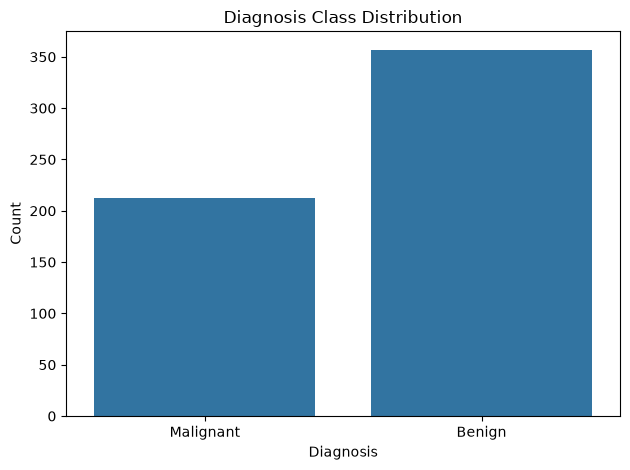

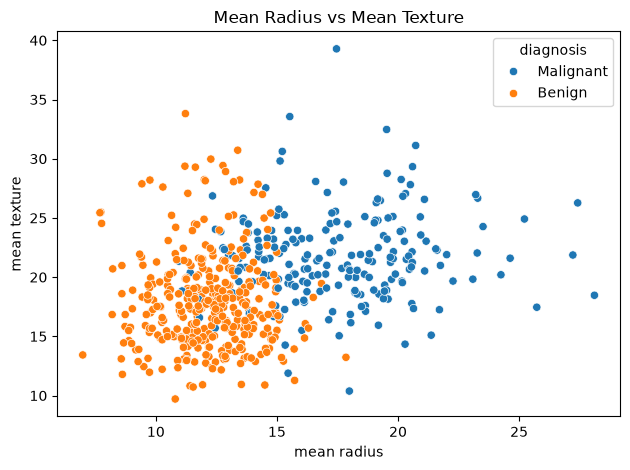

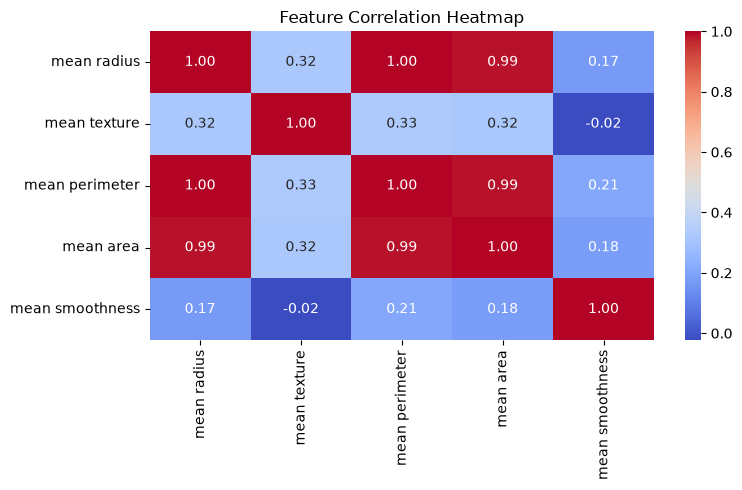


Model Comparison
                Model  Accuracy
0  LogisticRegression  0.982456
1       Decision Tree  0.938596


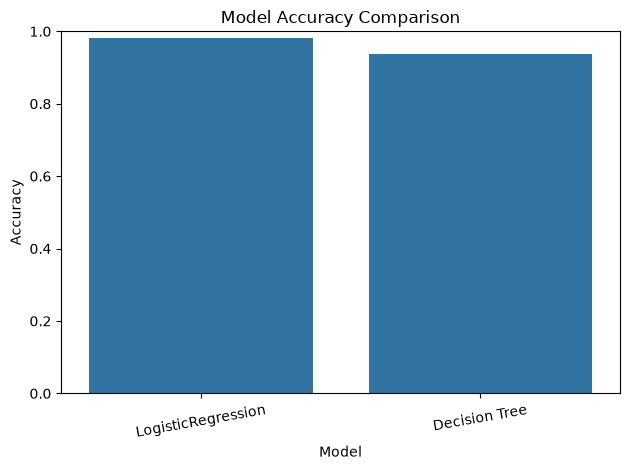

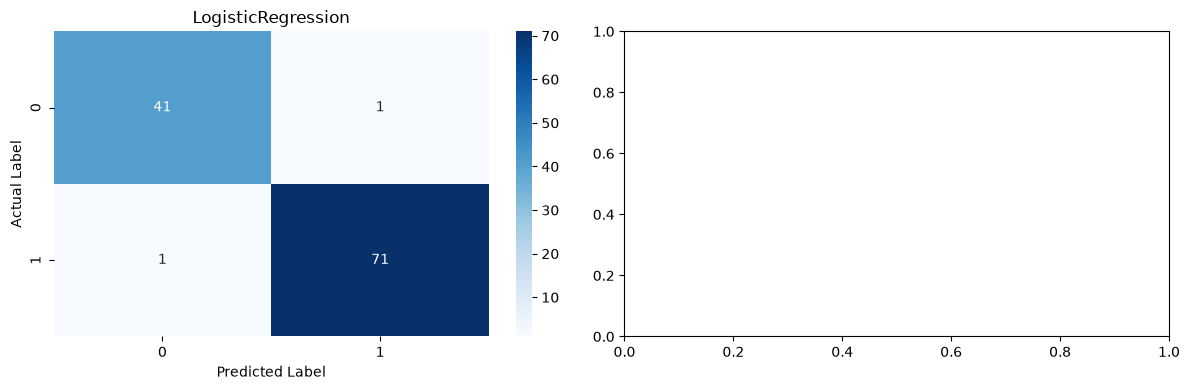


Logistic Regression Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


Decision Tree Report:
              precision    recall  f1-score   support

   malignant       0.91      0.93      0.92        42
      benign       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114



<Figure size 640x480 with 0 Axes>


Logistic Regression Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


Decision Tree Report:
              precision    recall  f1-score   support

   malignant       0.91      0.93      0.92        42
      benign       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114



In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

# 1. load dataset
data = load_breast_cancer()
df = pd.DataFrame(data.data,columns=data.feature_names)
df["target"] = data.target

# 0 =Malignant, 1=Benign
df["diagnosis"] = df["target"].map({0:"Malignant",1:"Benign"})

print("First 5 rows:")
print(df.head())

print("\nData shape:")
print(df.shape)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nClass distribution:")
print(df["diagnosis"].value_counts())

# 2. Visualization with Seaborn
sns.countplot(data=df,x="diagnosis")
plt.title("Diagnosis Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# 3. Scatter plot
sns.scatterplot(
    data=df,
    x = "mean radius",
    y ="mean texture",
    hue="diagnosis"
    )
plt.title("Mean Radius vs Mean Texture")
plt.tight_layout()
plt.show()

# 4. Correlation heatmap (selected_features)
selected_features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area",
    "mean smoothness"
]

plt.figure(figsize=(8,5))
sns.heatmap(
    df[selected_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

# 5. Prepare features and target
x = df[data.feature_names]
y = df["target"]

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

# 6. Logistic Regression
log_model = make_pipeline(StandardScaler(),
LogisticRegression(max_iter=2000)
)
log_model.fit(x_train,y_train)
log_pred = log_model.predict(x_test)

# 7. Decision Tree
tree_model= DecisionTreeClassifier(max_depth=4,random_state=42)
tree_model.fit(x_train,y_train)
tree_pred = tree_model.predict(x_test)

# 8. Compare model accuracy
results = pd.DataFrame({
    "Model":["LogisticRegression","Decision Tree"],
    "Accuracy":[accuracy_score(y_test,log_pred),
                accuracy_score(y_test,tree_pred)]
})
print("\nModel Comparison")
print(results)

sns.barplot(data=results,x="Model",y="Accuracy")
plt.title("Model Accuracy Comparison")
plt.ylim(0,1)
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

# 9. Confusion matrices
fig, axes = plt.subplots(1,2,figsize=(12,4))

for ax, model_name, predictions in[
    (axes[0],"LogisticRegression",log_pred),
    (axes[1],"Decision Tree",tree_pred)
]:
    cm=confusion_matrix(y_test,predictions)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax
    )
    ax.set_title(model_name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")
    plt.tight_layout()
    plt.show()
    
    # 10. Classification report
    print("\nLogistic Regression Report:")
    print(classification_report(
        y_test,
        log_pred,
        target_names=data.target_names
    ))
    
    print("\nDecision Tree Report:")
    print(classification_report(
        y_test,
        tree_pred,
        
        target_names=data.target_names
    ))